# 법안 통과 가능성 예측 (Keras Dense, 이진 분류)

지난 21대 국회에서 같은 범위(국토교통·행정안전 등 건축·주택·안전 관련 법률)의 법안 1,087건이 **실제로 법에 반영됐는지**를 배워, 지금 22대 국회에 올라와 있는 법안의 반영 가능성을 추정한다.

- 이 숫자는 **법안의 좋고 나쁨과 무관**하다. 과거에 비슷한 법안이 어떻게 처리됐는지에서 나온 통계적 추정일 뿐이다.
- 제안한 의원 이름, 정당, 공동발의 의원 수 같은 **정치 관련 정보는 쓰지 않는다** (정치적 중립).
- 처리 단계·처리 날짜처럼 **결과가 나온 뒤에야 알 수 있는 정보도 쓰지 않는다** (정답 누설 방지).

**순서**: 1 문제 → 2 데이터 → 3 전처리 → 4 학습/테스트 분리 → 5 기준선 → 6 신경망 → 7 과적합 확인 → 8 은닉층 실험 → 9 오답 분석 → 10 결과표 → 11 화면에 쓰이는 곳

## 0. 준비 (Colab 한글 글꼴 설치)

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/usr/share/fonts/truetype/nanum'):
    !apt-get -qq install fonts-nanum > /dev/null

In [2]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'   # 컴퓨터가 달라도 계산 순서가 같도록 (결과 재현)
os.environ['OMP_NUM_THREADS'] = '1'
import re, json, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, roc_curve
from IPython.display import Markdown, display

import matplotlib.font_manager as fm
_f = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
if os.path.exists(_f):
    fm.fontManager.addfont(_f)                       # 새로 설치한 한글 글꼴 등록
    plt.rcParams['font.family'] = fm.FontProperties(fname=_f).get_name()
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # 다시 실행해도 같은 결과
tf.config.threading.set_intra_op_parallelism_threads(1); tf.config.threading.set_inter_op_parallelism_threads(1)

## 1. 문제
- **입력**: 법안이 제안된 날 알 수 있는 것만. 법안 이름, 제안이유 및 주요내용(요약), 소관 위원회.
- **정답(PASSED)**: 법안 내용이 법에 반영됐으면 1, 아니면 0.
  - 1 = 원안가결, 수정가결, **대안반영폐기**, 수정안반영폐기
  - 0 = 임기만료폐기, 철회, 부결, 폐기
- **대안반영폐기**는 이름에 '폐기'가 있지만, 위원회가 비슷한 법안 여러 건을 하나로 합친 **위원회 대안에 내용이 들어가 통과된 경우**다. 그래서 반영(1)으로 본다. 이 법안 하나만의 성과는 아니라는 점은 감안해야 한다.
- **주의(분포 변화)**: 21대 국회에서 배운 규칙을 22대 법안에 쓴다. 국회가 바뀌면 위원회 구성, 관심 주제, 처리 속도가 달라질 수 있어 시험 점수보다 실제 성능이 낮을 수 있다.

## 2. 데이터
GitHub 저장소의 `data/` 폴더에서 읽는다. 인터넷이 안 되면 저장소의 `data/` 폴더(또는 NB_LOCAL_DATA)를 읽는다.

In [3]:
BASE = 'https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/'

def load(name):
    try:
        return pd.read_csv(BASE + name, encoding='utf-8-sig', dtype={'BILL_NO': str})
    except Exception:
        for d in [os.environ.get('NB_LOCAL_DATA', ''), '../data', '.']:
            p = os.path.join(d, name)
            if d and os.path.exists(p):
                return pd.read_csv(p, encoding='utf-8-sig', dtype={'BILL_NO': str})
        from google.colab import files
        print(name, '파일을 올려 주세요'); files.upload()
        return pd.read_csv(name, encoding='utf-8-sig', dtype={'BILL_NO': str})

hist = load('bills_history_21.csv')   # 21대 국회 법안 (정답 있음)
cur = load('bills_summary.csv')       # 22대 국회 법안 (예측 대상)
print('21대(학습)', hist.shape, '/ 22대(예측)', cur.shape)
print()
print(hist['PROC_RESULT'].value_counts().to_string())
print()
print('반영(1) %d건 / 미반영(0) %d건 → 반영 비율 %.1f%%' % (hist.PASSED.sum(), (1 - hist.PASSED).sum(), 100 * hist.PASSED.mean()))

21대(학습) (1087, 9) / 22대(예측) (712, 7)

PROC_RESULT
임기만료폐기    647
대안반영폐기    319
수정가결       58
폐기         41
원안가결       13
철회          9

반영(1) 390건 / 미반영(0) 697건 → 반영 비율 35.9%


In [4]:
# 제안 연도별 반영 비율: 임기 끝 무렵에 낸 법안은 심사할 시간이 없어 대부분 임기만료폐기된다
hist['YEAR'] = hist['PROPOSE_DT'].str[:4]
by_year = hist.groupby('YEAR')['PASSED'].agg(['size', 'mean']).rename(columns={'size': '건수', 'mean': '반영 비율'}).round(3)
print(by_year.to_string())
print()
print(hist.groupby('COMMITTEE')['PASSED'].agg(['size', 'mean']).round(3).to_string())

       건수  반영 비율
YEAR            
2020  268  0.489
2021  290  0.445
2022  212  0.373
2023  302  0.169
2024   15  0.000

           size   mean
COMMITTEE             
국토교통위원회     803  0.337
행정안전위원회     272  0.419
환경노동위원회      12  0.417


위 표에서 보듯 **제안 시기가 늦을수록 반영 비율이 크게 떨어진다** (임기 막바지 법안은 심사할 시간이 없다). 22대 법안은 아직 임기 전반부라 사정이 다르다. 이 모델은 제안 날짜를 입력으로 쓰지 않으므로, 이 차이는 모델이 아니라 해석할 때 감안해야 한다 (4절 시간 분리, 10절 참고).

## 3. 전처리
| 특징 | 만드는 법 | 개수 |
|---|---|---|
| 글자 조각 TF-IDF | 법안 이름 + 요약의 2~3글자 조각, 학습 데이터로만 사전을 만듦 | 3,000 |
| 위원회 | 국토교통 / 행정안전 / 환경노동(22대 이름 기후에너지환경노동 포함) 원-핫 | 3 |
| 법안 종류 | 이름의 일부개정 / 전부개정 / 제정 / 폐지 표시 | 4 |
| 요약 길이 | log(글자 수), 표준화 | 1 |
| 같은 법률 법안 수 | 학습 데이터에 같은 법률 개정안이 몇 건 있었는지 log(1+n), 표준화 | 1 |

같은 법률 법안 수는 정답(PASSED)을 쓰지 않는 단순 빈도이고, 시험 데이터는 학습 데이터에서 센 값만 쓴다 (누설 방지).

In [5]:
def clean(t):
    t = str(t) if isinstance(t, str) else ''
    t = re.sub(r'^\s*제안이유\s*(및\s*주요내용)?', '', t)
    return re.sub(r'\s+', ' ', t).strip()

def law_name(n):
    n = re.sub(r'\s*(일부|전부)개정법률안.*|\s*(제정|폐지)?법률안.*', '', str(n))
    return re.sub(r'\(.*?\)', '', n).strip()

COMMS = ['국토교통', '행정안전', '환경노동']
def comm(c):
    c = str(c)
    for k in COMMS:
        if k in c:
            return k
    return '환경노동'   # 그 밖(없음)

KINDS = ['일부개정', '전부개정', '제정', '폐지']

def prep(df):
    df = df.copy()
    df['TEXT'] = df['BILL_NAME'].fillna('') + ' ' + df['SUMMARY'].map(clean)
    df['LAW'] = df['BILL_NAME'].map(law_name)
    df['COMM'] = df['COMMITTEE'].map(comm)
    df['LEN'] = np.log(df['SUMMARY'].map(clean).str.len().clip(lower=1))
    return df

hist = prep(hist); cur = prep(cur)
print('위원회(21대):', hist.COMM.value_counts().to_dict(), '/ (22대):', cur.COMM.value_counts().to_dict())
for k in KINDS:
    print(f'{k}: 21대 {hist.BILL_NAME.str.contains(k).sum()}건, 22대 {cur.BILL_NAME.str.contains(k).sum()}건')
print('법률 이름 예:', hist.LAW.value_counts().head(5).to_dict())

위원회(21대): {'국토교통': 803, '행정안전': 272, '환경노동': 12} / (22대): {'국토교통': 522, '행정안전': 184, '환경노동': 6}
일부개정: 21대 1051건, 22대 698건
전부개정: 21대 1건, 22대 0건
제정: 21대 0건, 22대 0건
폐지: 21대 0건, 22대 2건
법률 이름 예: {'재난 및 안전관리 기본법': 145, '주택법': 104, '공동주택관리법': 86, '공공주택 특별법': 84, '건축법': 81}


21대·22대 모두 거의 전부 **일부개정**이라 법안 종류 표시는 구분력이 거의 없다. 그래도 제정·폐지 법안이 들어올 때를 위해 넣어 둔다.

In [6]:
class Features:
    # 학습 데이터로만 fit 하고, 시험·22대 데이터는 transform 만 한다
    def fit(self, df):
        self.vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 3), max_features=3000, sublinear_tf=True).fit(df['TEXT'])
        self.law_n = df['LAW'].value_counts()
        self.scaler = StandardScaler().fit(self._num(df, train=True))
        return self

    def _num(self, df, train=False):
        n = df['LAW'].map(self.law_n).fillna(0).values
        if train:
            n = n - 1                                   # 학습 데이터에서는 자기 자신을 뺀 수
        return np.c_[df['LEN'].values, np.log1p(n)]

    def transform(self, df, train=False):
        txt = self.vec.transform(df['TEXT']).toarray()
        oh = np.c_[[(df['COMM'] == k).values for k in COMMS]].T
        kind = np.c_[[df['BILL_NAME'].str.contains(k).values for k in KINDS]].T
        num = self.scaler.transform(self._num(df, train))
        return np.hstack([txt, oh, kind, num]).astype('float32')

    def names(self):
        return list(self.vec.get_feature_names_out()) + ['위원회_' + k for k in COMMS] + KINDS + ['요약길이', '같은법률수']

## 4. 학습/테스트 분리
- **기본**: 8:2 무작위 분리, 반영 비율이 같도록 층화(stratify). 학습 쪽에서 다시 15%를 떼어 검증용으로 쓴다 (조기 종료, 문턱값 고르기).
- **점검용 시간 분리**: 먼저 제안된 80%로 학습하고 나중에 제안된 20%로 시험한다. 과거로 미래를 맞히는 실제 상황에 더 가깝다 (6절 끝에서 확인).

In [7]:
tr_all, te = train_test_split(hist, test_size=0.2, random_state=SEED, stratify=hist['PASSED'])
tr, va = train_test_split(tr_all, test_size=0.15, random_state=SEED, stratify=tr_all['PASSED'])

feat = Features().fit(tr)
X_tr, X_va, X_te = feat.transform(tr, train=True), feat.transform(va), feat.transform(te)
y_tr, y_va, y_te = tr['PASSED'].values, va['PASSED'].values, te['PASSED'].values
print('학습', X_tr.shape, '/ 검증', X_va.shape, '/ 시험', X_te.shape)
print('반영 비율  학습 %.3f / 검증 %.3f / 시험 %.3f' % (y_tr.mean(), y_va.mean(), y_te.mean()))

# 시간 분리
h_sorted = hist.sort_values(['PROPOSE_DT', 'BILL_NO'])
cut = int(len(h_sorted) * 0.8)
t_tr, t_te = h_sorted.iloc[:cut], h_sorted.iloc[cut:]
print('시간 분리  학습 %s ~ %s (반영 %.3f) / 시험 %s ~ %s (반영 %.3f)' % (
    t_tr.PROPOSE_DT.min(), t_tr.PROPOSE_DT.max(), t_tr.PASSED.mean(), t_te.PROPOSE_DT.min(), t_te.PROPOSE_DT.max(), t_te.PASSED.mean()))

학습 (738, 3009) / 검증 (131, 3009) / 시험 (218, 3009)
반영 비율  학습 0.359 / 검증 0.359 / 시험 0.358
시간 분리  학습 2020-06-01 ~ 2023-04-21 (반영 0.418) / 시험 2023-04-21 ~ 2024-03-05 (반영 0.124)


## 5. 기준선
신경망이 의미 있으려면 아래 단순한 방법들보다 나아야 한다.
1. **다수 클래스**: 모든 법안을 '미반영'으로 찍는다. 정확도가 이미 64% 안팎이라 정확도만 보면 속기 쉽다. 그래서 AUC와 F1을 함께 본다.
2. **위원회 반영 비율 규칙**: 학습 데이터에서 위원회별 반영 비율을 그대로 확률로 쓴다.
3. **법률별 반영 비율 규칙**: 같은 법률 개정안의 학습 데이터 반영 비율(건수가 적으면 전체 평균 쪽으로 당김).
4. **로지스틱 회귀**: 신경망과 같은 특징을 쓰는 선형 모델 (은닉층이 없는 신경망과 같다).

확률을 0/1로 바꾸는 문턱값은 모든 모델에서 **검증 데이터의 F1이 가장 높은 값**으로 고른다 (시험 데이터는 고르는 데 쓰지 않음). 구분력이 약한 규칙은 이렇게 고르면 문턱값이 아주 낮아져 사실상 '전부 반영'으로 찍게 되고, 그러면 F1은 0.5 남짓 나오지만 정확도는 36%로 떨어진다. 그래서 규칙은 AUC로 비교하는 것이 공정하다.

In [8]:
def best_threshold(y, p):
    ts = np.round(np.arange(0.10, 0.71, 0.01), 2)
    f = [f1_score(y, p >= t, zero_division=0) for t in ts]
    return float(ts[int(np.argmax(f))])

def scores(y, p, t):
    return {'정확도': accuracy_score(y, p >= t), 'AUC': roc_auc_score(y, p), 'F1': f1_score(y, p >= t, zero_division=0)}

results = {}
majority_acc = accuracy_score(y_te, np.zeros_like(y_te))
results['다수 클래스(전부 미반영)'] = {'정확도': majority_acc, 'AUC': 0.5, 'F1': 0.0, '문턱값': None}

base = y_tr.mean()
cr = tr.groupby('COMM')['PASSED'].mean()
p_va, p_te = va['COMM'].map(cr).fillna(base).values, te['COMM'].map(cr).fillna(base).values
t = best_threshold(y_va, p_va); results['위원회 반영 비율 규칙'] = {**scores(y_te, p_te, t), '문턱값': t}

K = 5   # 법률별 비율을 전체 평균 쪽으로 당기는 세기 (가상의 평균 법안 5건을 더한 것)
g = tr.groupby('LAW')['PASSED'].agg(['sum', 'size'])
lr_rate = (g['sum'] + K * base) / (g['size'] + K)
p_va, p_te = va['LAW'].map(lr_rate).fillna(base).values, te['LAW'].map(lr_rate).fillna(base).values
t = best_threshold(y_va, p_va); results['법률별 반영 비율 규칙'] = {**scores(y_te, p_te, t), '문턱값': t}

logreg = LogisticRegression(C=3, solver='liblinear').fit(X_tr, y_tr)
p_va_lr, p_te_lr = logreg.predict_proba(X_va)[:, 1], logreg.predict_proba(X_te)[:, 1]
t = best_threshold(y_va, p_va_lr); results['로지스틱 회귀(같은 특징)'] = {**scores(y_te, p_te_lr, t), '문턱값': t}

pd.DataFrame(results).T.astype(float).round(3)

,정확도,AUC,F1,문턱값
다수 클래스(전부 미반영),0.642,0.500,0.000,NaN
위원회 반영 비율 규칙,0.358,0.508,0.527,0.10
법률별 반영 비율 규칙,0.362,0.591,0.526,0.20
로지스틱 회귀(같은 특징),0.647,0.749,0.617,0.28


In [9]:
# 로지스틱 회귀가 '반영' 쪽으로 가장 크게 본 특징과 '미반영' 쪽으로 본 특징 (해석용)
w = pd.Series(logreg.coef_[0], index=feat.names())
print('반영 쪽:', ', '.join(f'{k}({v:.2f})' for k, v in w.nlargest(15).items()))
print('미반영 쪽:', ', '.join(f'{k}({v:.2f})' for k, v in w.nsmallest(15).items()))

반영 쪽:  해체(1.30), 해체(1.24), 방시(1.20), 지구(1.17), 1항)(1.13), 소방시(1.10),  거(1.08), 적용(1.08),  전세(1.08),  적용(1.05), 보증금(1.04), 증금(1.04), 정되(1.03), 방시설(1.03), 과하(1.01)
미반영 쪽:  가(-1.55), 형 (-1.38), 설계(-1.04), 무에 (-1.00),  아(-1.00), 지만(-0.99), 때 (-0.96),  때 (-0.96),  설계(-0.96),  정하(-0.95),  빈(-0.95), 학교(-0.94),  세(-0.94),  건설(-0.93),  구(-0.93)


## 6. 신경망
- 구조: 입력 3,009 → Dense(ReLU) → Dropout 0.3 → Dense 1 (sigmoid). 출력은 0~1 사이의 반영 확률.
- 손실: binary cross-entropy, 최적화: Adam.
- **클래스 불균형 처리**: 반영이 36%로 적다. `class_weight`로 반영 법안에 가중치를 주면 F1은 오르지만 **출력 확률이 실제보다 부풀려진다** (화면에 '42%'라고 쓰면 실제 비율과 달라진다). 그래서 가중치 없이 학습해 확률을 실제 비율에 가깝게 두고, 대신 **문턱값을 0.5보다 낮게**(검증 F1 최대) 골라 불균형을 처리한다. 아래에서 두 방법을 비교한다.
- 조기 종료: 검증 손실이 5 epoch 동안 나아지지 않으면 멈추고 가장 좋았던 가중치로 되돌린다.

In [10]:
HIDDEN = (16,)   # 8절 실험에서 시험 AUC 평균이 가장 높고 시드에 따른 흔들림이 작았던 구조

def build(hidden=HIDDEN, seed=SEED, dropout=0.3, n_in=None):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(n_in or X_tr.shape[1],))])
    for h in hidden:
        m.add(Dense(h, activation='relu'))
        m.add(Dropout(dropout))
    m.add(Dense(1, activation='sigmoid'))
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(name='auc')])
    return m

def fit(m, X, y, Xv, yv, class_weight=None, epochs=60):
    es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    return m.fit(X, y, validation_data=(Xv, yv), epochs=epochs, batch_size=32, verbose=0,
                 class_weight=class_weight, callbacks=[es])

model = build()
model.summary()
h = fit(model, X_tr, y_tr, X_va, y_va)
BEST_EPOCH = int(np.argmin(h.history['val_loss'])) + 1
p_va_nn = model.predict(X_va, verbose=0).ravel()
p_te_nn = model.predict(X_te, verbose=0).ravel()
THRESHOLD = best_threshold(y_va, p_va_nn)
results['신경망 Dense' + str(HIDDEN)] = {**scores(y_te, p_te_nn, THRESHOLD), '문턱값': THRESHOLD}
print('가장 좋았던 epoch', BEST_EPOCH, '/ 고른 문턱값', THRESHOLD)
print('시험 평균 확률 %.3f (실제 반영 비율 %.3f)' % (p_te_nn.mean(), y_te.mean()))
pd.DataFrame(results).T.astype(float).round(3)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │        48,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,177 (188.19 KB)

 Trainable params: 48,177 (188.19 KB)

 Non-trainable params: 0 (0.00 B)

E0000 00:00:1795367885.625871    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


가장 좋았던 epoch 13 / 고른 문턱값 0.26
시험 평균 확률 0.322 (실제 반영 비율 0.358)


,정확도,AUC,F1,문턱값
다수 클래스(전부 미반영),0.642,0.500,0.000,NaN
위원회 반영 비율 규칙,0.358,0.508,0.527,0.10
법률별 반영 비율 규칙,0.362,0.591,0.526,0.20
로지스틱 회귀(같은 특징),0.647,0.749,0.617,0.28
"신경망 Dense(16,)",0.633,0.737,0.615,0.26


In [11]:
# 비교: class_weight 로 반영 법안에 가중치를 준 경우
n0, n1 = (y_tr == 0).sum(), (y_tr == 1).sum()
cw = {0: len(y_tr) / (2 * n0), 1: len(y_tr) / (2 * n1)}
m_cw = build(); fit(m_cw, X_tr, y_tr, X_va, y_va, class_weight=cw)
p_cw = m_cw.predict(X_te, verbose=0).ravel()
print('class_weight', {k: round(v, 2) for k, v in cw.items()})
print('가중치 있음, 문턱값 0.5:  ', {k: round(v, 3) for k, v in scores(y_te, p_cw, 0.5).items()}, ' 평균 확률 %.3f' % p_cw.mean())
print('가중치 없음, 문턱값 %.2f: ' % THRESHOLD, {k: round(v, 3) for k, v in scores(y_te, p_te_nn, THRESHOLD).items()}, ' 평균 확률 %.3f' % p_te_nn.mean())
print('실제 반영 비율 %.3f' % y_te.mean())

class_weight {0: np.float64(0.78), 1: np.float64(1.39)}
가중치 있음, 문턱값 0.5:   {'정확도': 0.683, 'AUC': 0.75, 'F1': 0.537}  평균 확률 0.413
가중치 없음, 문턱값 0.26:  {'정확도': 0.633, 'AUC': 0.737, 'F1': 0.615}  평균 확률 0.322
실제 반영 비율 0.358


In [12]:
# 실행 결과 해설 (숫자는 위 실행 결과에서 그대로 가져온다)
s_cw, s_nn = scores(y_te, p_cw, 0.5), scores(y_te, p_te_nn, THRESHOLD)
display(Markdown(
    f"**실행 결과**: 가중치를 주면 문턱값 0.5에서 정확도 {s_cw['정확도']:.3f}, F1 {s_cw['F1']:.3f}이고, 시험 평균 확률이 {p_cw.mean():.3f}로 "
    f"실제 반영 비율({y_te.mean():.3f})보다 부풀려진다. 가중치 없이 문턱값 {THRESHOLD}을 쓰면 F1 {s_nn['F1']:.3f}, 평균 확률 {p_te_nn.mean():.3f}로 "
    f"실제 비율에 더 가깝다. 화면에 확률(%)을 그대로 보여 주므로 가중치 없는 쪽을 쓴다."))

**실행 결과**: 가중치를 주면 문턱값 0.5에서 정확도 0.683, F1 0.537이고, 시험 평균 확률이 0.413로 실제 반영 비율(0.358)보다 부풀려진다. 가중치 없이 문턱값 0.26을 쓰면 F1 0.615, 평균 확률 0.322로 실제 비율에 더 가깝다. 화면에 확률(%)을 그대로 보여 주므로 가중치 없는 쪽을 쓴다.

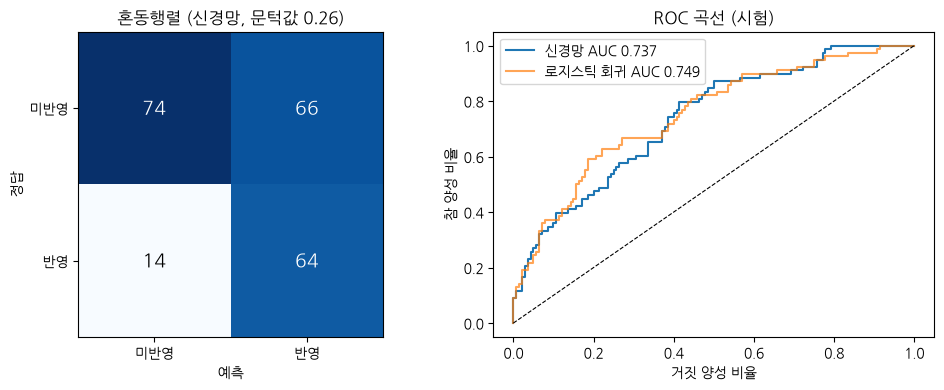

In [13]:
cm = confusion_matrix(y_te, p_te_nn >= THRESHOLD)
fpr, tpr, _ = roc_curve(y_te, p_te_nn); fpr2, tpr2, _ = roc_curve(y_te, p_te_lr)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(['미반영', '반영']); ax[0].set_yticklabels(['미반영', '반영'])
ax[0].set_xlabel('예측'); ax[0].set_ylabel('정답'); ax[0].set_title(f'혼동행렬 (신경망, 문턱값 {THRESHOLD})')
ax[1].plot(fpr, tpr, label='신경망 AUC %.3f' % roc_auc_score(y_te, p_te_nn))
ax[1].plot(fpr2, tpr2, label='로지스틱 회귀 AUC %.3f' % roc_auc_score(y_te, p_te_lr), alpha=0.7)
ax[1].plot([0, 1], [0, 1], 'k--', lw=0.8); ax[1].set_xlabel('거짓 양성 비율'); ax[1].set_ylabel('참 양성 비율'); ax[1].set_title('ROC 곡선 (시험)'); ax[1].legend()
plt.tight_layout(); plt.show()

### 6-2. 점검: 시간 분리 (먼저 낸 80%로 학습 → 나중에 낸 20% 시험)
나중에 낸 법안은 임기 막바지라 반영 비율 자체가 매우 낮다. 그래서 정확도·F1보다 **순서를 맞히는 능력(AUC)**이 유지되는지를 본다.

In [14]:
t_tr2, t_va2 = train_test_split(t_tr, test_size=0.15, random_state=SEED, stratify=t_tr['PASSED'])
f2 = Features().fit(t_tr2)
A, Av, B = f2.transform(t_tr2, train=True), f2.transform(t_va2), f2.transform(t_te)
yA, yAv, yB = t_tr2.PASSED.values, t_va2.PASSED.values, t_te.PASSED.values
lr2 = LogisticRegression(C=3, solver='liblinear').fit(A, yA)
nn2 = build(n_in=A.shape[1]); fit(nn2, A, yA, Av, yAv)
time_split = pd.DataFrame({
    '로지스틱 회귀': {'AUC': roc_auc_score(yB, lr2.predict_proba(B)[:, 1])},
    '신경망': {'AUC': roc_auc_score(yB, nn2.predict(B, verbose=0).ravel())},
}).T
time_split['시험 평균 확률'] = [lr2.predict_proba(B)[:, 1].mean(), nn2.predict(B, verbose=0).ravel().mean()]
time_split['시험 실제 반영 비율'] = yB.mean()
time_split.round(3)

E0000 00:00:1795367891.328586    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


,AUC,시험 평균 확률,시험 실제 반영 비율
로지스틱 회귀,0.642,0.371,0.124
신경망,0.624,0.341,0.124


시간 분리에서 AUC가 무작위 분리보다 얼마나 떨어지는지가 **새 국회(22대)에 쓸 때의 성능 하락**을 짐작하게 한다. 평균 확률이 실제 반영 비율보다 높게 나오는 것도 같은 이유(시기에 따른 반영 비율 변화)다.

## 7. 과적합 확인
학습 손실은 계속 내려가는데 검증 손실이 올라가기 시작하면 외우기(과적합)가 시작된 것이다. 조기 종료 없이 40 epoch을 끝까지 학습한 곡선과 비교한다.

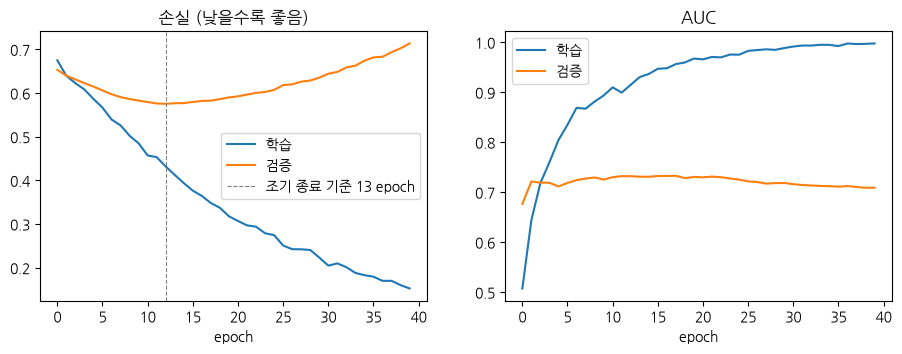

조기 종료            학습 AUC 0.948 / 시험 AUC 0.737   학습 정확도 0.783 / 시험 정확도 0.633
40 epoch 끝까지     학습 AUC 1.000 / 시험 AUC 0.752   학습 정확도 0.973 / 시험 정확도 0.683


E0000 00:00:1795367896.341385    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


In [15]:
m_long = build()
h_long = m_long.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=40, batch_size=32, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h_long.history['loss'], label='학습'); ax[0].plot(h_long.history['val_loss'], label='검증')
ax[0].axvline(BEST_EPOCH - 1, color='gray', ls='--', lw=0.8, label=f'조기 종료 기준 {BEST_EPOCH} epoch')
ax[0].set_title('손실 (낮을수록 좋음)'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(h_long.history['auc'], label='학습'); ax[1].plot(h_long.history['val_auc'], label='검증')
ax[1].set_title('AUC'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.show()

show_res = {}
def show(name, m):
    p_a = m.predict(X_tr, verbose=0).ravel(); p_b = m.predict(X_te, verbose=0).ravel()
    show_res[name] = (roc_auc_score(y_tr, p_a), roc_auc_score(y_te, p_b))
    print(f'{name:16s} 학습 AUC {roc_auc_score(y_tr, p_a):.3f} / 시험 AUC {roc_auc_score(y_te, p_b):.3f}   '
          f'학습 정확도 {accuracy_score(y_tr, p_a >= THRESHOLD):.3f} / 시험 정확도 {accuracy_score(y_te, p_b >= THRESHOLD):.3f}')
show('조기 종료', model)
show('40 epoch 끝까지', m_long)

학습 데이터가 738건인데 입력이 3,009개라 신경망은 학습 데이터를 금방 거의 다 외운다. 학습 AUC와 시험 AUC의 차이가 과적합의 크기다. 그래서 작은 은닉층, Dropout, 조기 종료를 함께 쓴다.

끝까지 학습해 학습 데이터를 다 외워도 시험 AUC가 크게 떨어지지 않을 수 있는데, AUC는 **순서**만 보기 때문이다. 그 사이 검증 손실이 올라가는 것은 확률이 0이나 1 쪽으로 쏠려 **과신**한다는 뜻이다. 화면에는 확률(%)을 그대로 보여 주므로 순서보다 확률이 믿을 만한 쪽이 중요하다. 그래서 검증 손실 기준 조기 종료를 쓴다.

In [16]:
display(Markdown(
    f"**실행 결과**: 조기 종료({BEST_EPOCH} epoch) 모델은 학습 AUC {show_res['조기 종료'][0]:.3f} / 시험 AUC {show_res['조기 종료'][1]:.3f}, "
    f"40 epoch 끝까지 학습한 모델은 학습 AUC {show_res['40 epoch 끝까지'][0]:.3f} / 시험 AUC {show_res['40 epoch 끝까지'][1]:.3f}, "
    f"검증 손실은 최저 {min(h_long.history['val_loss']):.3f}에서 마지막 {h_long.history['val_loss'][-1]:.3f}로 올라갔다."))

**실행 결과**: 조기 종료(13 epoch) 모델은 학습 AUC 0.948 / 시험 AUC 0.737, 40 epoch 끝까지 학습한 모델은 학습 AUC 1.000 / 시험 AUC 0.752, 검증 손실은 최저 0.575에서 마지막 0.713로 올라갔다.

## 8. 은닉층 실험
같은 데이터로 구조마다 시드 3개(42, 43, 44)씩 학습해 시험 AUC의 평균과 흔들림을 본다. 시험 데이터가 218건뿐이라 0.01~0.02 차이는 우연일 수 있다.

In [17]:
rows = []
for hidden in [(16,), (64,), (256,), (256, 64), (512, 256)]:
    aucs, f1s, eps = [], [], []
    for s in range(3):
        m = build(hidden, seed=SEED + s)
        hh = fit(m, X_tr, y_tr, X_va, y_va)
        pv, pt = m.predict(X_va, verbose=0).ravel(), m.predict(X_te, verbose=0).ravel()
        aucs.append(roc_auc_score(y_te, pt)); f1s.append(f1_score(y_te, pt >= best_threshold(y_va, pv)))
        eps.append(int(np.argmin(hh.history['val_loss'])) + 1)
    rows.append({'은닉층': str(hidden), '매개변수 수': m.count_params(), '시험 AUC 평균': np.mean(aucs), '최저': min(aucs), '최고': max(aucs),
                 '시험 F1 평균': np.mean(f1s), '멈춘 epoch': str(eps)})
exp = pd.DataFrame(rows).round(3)
exp

E0000 00:00:1795367902.503316    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367907.864179    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367913.830353    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367919.902652    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1795367925.715165    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,은닉층,매개변수 수,시험 AUC 평균,최저,최고,시험 F1 평균,멈춘 epoch
0,"(16,)",48177,0.738,0.735,0.742,0.616,"[13, 12, 14]"
1,"(64,)",192705,0.734,0.725,0.745,0.611,"[7, 7, 7]"
2,"(256,)",770817,0.731,0.725,0.738,0.604,"[4, 4, 4]"
3,"(256, 64)",787073,0.724,0.723,0.727,0.578,"[3, 3, 4]"
4,"(512, 256)",1672705,0.714,0.705,0.728,0.557,"[2, 2, 3]"


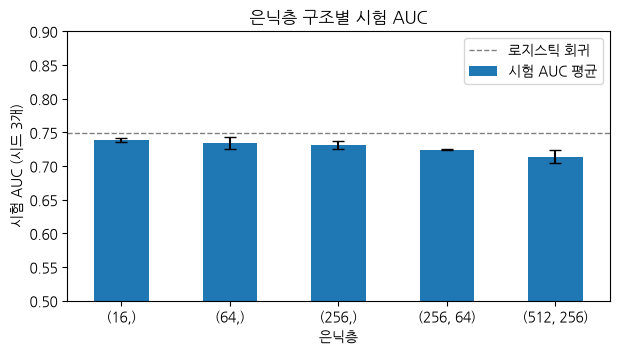

In [18]:
ax = exp.set_index('은닉층')[['시험 AUC 평균']].plot.bar(yerr=[exp['시험 AUC 평균'] - exp['최저'], exp['최고'] - exp['시험 AUC 평균']],
                                                       figsize=(7, 3.5), rot=0, legend=False, capsize=4)
ax.axhline(results['로지스틱 회귀(같은 특징)']['AUC'], color='gray', ls='--', lw=1, label='로지스틱 회귀')
ax.set_ylim(0.5, 0.9); ax.set_ylabel('시험 AUC (시드 3개)'); ax.set_title('은닉층 구조별 시험 AUC'); ax.legend()
plt.show()

In [19]:
best = exp.sort_values('시험 AUC 평균', ascending=False).iloc[0]
big = exp.iloc[-1]
display(Markdown(
    f"**실행 결과**: 시험 AUC 평균이 가장 높은 구조는 {best['은닉층']} ({best['시험 AUC 평균']:.3f}, 시드별 {best['최저']:.3f}~{best['최고']:.3f})이고, "
    f"가장 큰 {big['은닉층']}은 {big['시험 AUC 평균']:.3f}이다. 층을 키울수록 몇 epoch 만에 학습 데이터를 외워 버려(멈춘 epoch 열) 오히려 나빠진다. "
    f"법안이 1,087건뿐이라 작은 신경망이 맞고, 6절의 구조 {HIDDEN}는 이 실험으로 정했다. "
    f"같은 특징의 로지스틱 회귀 AUC는 {results['로지스틱 회귀(같은 특징)']['AUC']:.3f}로, 은닉층을 둔 효과는 크지 않다."))

**실행 결과**: 시험 AUC 평균이 가장 높은 구조는 (16,) (0.738, 시드별 0.735~0.742)이고, 가장 큰 (512, 256)은 0.714이다. 층을 키울수록 몇 epoch 만에 학습 데이터를 외워 버려(멈춘 epoch 열) 오히려 나빠진다. 법안이 1,087건뿐이라 작은 신경망이 맞고, 6절의 구조 (16,)는 이 실험으로 정했다. 같은 특징의 로지스틱 회귀 AUC는 0.749로, 은닉층을 둔 효과는 크지 않다.

## 9. 오답 분석
신경망이 확신을 갖고 틀린 법안을 본다.
- **반영될 것 같다고 했는데 미반영**: 처리 결과(PROC_RESULT)가 대부분 임기만료폐기인지, 제안 시기가 늦은지 확인한다.
- **안 될 것 같다고 했는데 반영**: 대안반영폐기(다른 법안과 합쳐져 반영)가 많은지 확인한다.

In [20]:
te_r = te.copy()
te_r['확률'] = p_te_nn.round(3)
te_r['예측'] = (p_te_nn >= THRESHOLD).astype(int)
te_r['요약(앞부분)'] = te_r['SUMMARY'].map(clean).str[:70]
wrong = te_r[te_r['예측'] != te_r['PASSED']]
print('시험 %d건 중 오답 %d건' % (len(te_r), len(wrong)))
print()
print('처리 결과별 오답 비율:')
print(te_r.assign(오답=te_r['예측'] != te_r['PASSED']).groupby('PROC_RESULT')['오답'].agg(['size', 'mean']).round(3).to_string())
print()
print('제안 연도별 오답 비율:')
print(te_r.assign(오답=te_r['예측'] != te_r['PASSED']).groupby('YEAR')['오답'].agg(['size', 'mean']).round(3).to_string())

시험 218건 중 오답 80건

처리 결과별 오답 비율:
             size   mean
PROC_RESULT             
대안반영폐기         65  0.185
수정가결            9  0.111
원안가결            4  0.250
임기만료폐기        129  0.481
철회              1  1.000
폐기             10  0.300

제안 연도별 오답 비율:
      size   mean
YEAR             
2020    54  0.352
2021    60  0.350
2022    42  0.262
2023    58  0.448
2024     4  0.750


In [21]:
pd.set_option('display.max_colwidth', 80)
cols = ['BILL_NO', 'BILL_NAME', 'PROPOSE_DT', 'PROC_RESULT', '확률', '요약(앞부분)']
print('반영될 것 같다고 했는데 미반영 (확률 높은 순 5건)')
display(wrong[wrong.PASSED == 0].sort_values('확률', ascending=False)[cols].head(5))
print('안 될 것 같다고 했는데 반영 (확률 낮은 순 5건)')
display(wrong[wrong.PASSED == 1].sort_values('확률')[cols].head(5))

반영될 것 같다고 했는데 미반영 (확률 높은 순 5건)


,BILL_NO,BILL_NAME,PROPOSE_DT,PROC_RESULT,확률,요약(앞부분)
391,2117921,"화재예방, 소방시설 설치·유지 및 안전관리에 관한 법률 일부개정법률안",2022-10-26,임기만료폐기,0.659,"현행법은 특정소방대상물의 관계인이 소방시설을 화재안전기준에 따라 설치ㆍ관리하도록 규정하면서 특히 피난시설, 방화구획 또는 방화"
663,2110820,주택법 일부개정법률안,2021-06-16,임기만료폐기,0.642,현행법은 투기과열지구 및 조정대상지역의 지정은 그 지정 목적을 달성할 수 있는 최소한의 범위에서 시？군？구 또는 읍？면？동 단
500,2114988,국토의 계획 및 이용에 관한 법률 일부개정법률안,2022-03-28,임기만료폐기,0.632,현행법은 지구단위계획구역에서 용도지역 변경을 포함한 용적률 완화 등의 조치를 시행하는 경우 기반시설 설치 등 공공기여를 받을
407,2117506,재건축초과이익 환수에 관한 법률 일부개정법률안,2022-09-23,철회,0.589,국토교통부장관은 재건축사업으로 정상주택가격상승분 등을 제외한 조합원 1인당 평균 이익이 3천만 원을 초과하였을 경우 현행법 제
513,2114665,소방기본법 일부개정법률안,2022-02-04,임기만료폐기,0.552,소방청의 조직과 직무범위 그 밖에 필요한 사항을 따로 법률로 정하는 「소방조직법안」이 발의됨에 따라 이와 연계하여 “시？도지사


안 될 것 같다고 했는데 반영 (확률 낮은 순 5건)


,BILL_NO,BILL_NAME,PROPOSE_DT,PROC_RESULT,확률,요약(앞부분)
481,2115514,도시 및 주거환경정비법 일부개정법률안,2022-05-06,대안반영폐기,0.153,현행법은 총회는 조합장이 직권으로 소집하거나 조합원 5분의 1 이상(정관의 기재사항 중 제40조제1항제6호에 따른 조합임원의
538,2113932,공공주택 특별법 일부개정법률안,2021-12-16,대안반영폐기,0.157,현행법은 공공임대주택에 대하여 5년 이상의 범위에서 대통령령으로 정한 임대의무기간이 지나지 아니하면 공공주택사업자가 매각할 수
973,2102850,건설기술 진흥법 일부개정법률안,2020-08-10,대안반영폐기,0.161,"현행법은 “건설기술”에 “용역”을 덧붙여 “건설기술용역”이라는 용어를 두루 사용하고 있고, 건설기술용역을 다른 사람의 위탁을"
1084,2100023,주택법 일부개정법률안,2020-06-01,대안반영폐기,0.162,■ 제안이유 및 주요내용 사업주체가 건설ㆍ공급하는 주택을 거짓이나 부정한 방법으로 공급받는 등 주택의 공급질서를 위반한 자에
1047,2100812,공동주택관리법 일부개정법률안,2020-06-22,대안반영폐기,0.167,"현행법은 사업주체에게 하자보수를 보장하기 위하여 담보책임기간동안 하자보수보증금을 예치하도록 의무를 부여하고 있고, 보증금의 사"


읽는 법:
- **반영될 것 같다고 했는데 미반영**은 대부분 **임기만료폐기**다. 소방시설, 주택, 국토계획처럼 반영이 잦은 주제라도 심사 순서가 오지 않으면 폐기된다. 요약 글만으로는 알 수 없는 사정이다.
- **안 될 것 같다고 했는데 반영**은 대부분 **대안반영폐기**다. 위원회가 비슷한 법안을 묶어 대안을 만들 때 함께 반영된 경우라, 법안 자체의 글보다 같은 시기에 비슷한 법안이 있었는지가 더 중요하다.
- 2023년 이후(임기 막바지) 제안된 법안은 오답이 많다. 모델이 제안 시기를 모르기 때문이다 (2절 연도별 표).

In [22]:
err = te_r.assign(오답=te_r['예측'] != te_r['PASSED'])
fn5 = wrong[wrong.PASSED == 1].sort_values('확률').head(5)
display(Markdown(
    f"**실행 결과**: 시험 {len(te_r)}건 중 오답 {len(wrong)}건. 임기만료폐기 법안의 오답 비율 {err[err.PROC_RESULT == '임기만료폐기']['오답'].mean():.0%}, "
    f"대안반영폐기 {err[err.PROC_RESULT == '대안반영폐기']['오답'].mean():.0%}. 확률이 가장 낮았던 반영 법안 5건 중 대안반영폐기 {(fn5.PROC_RESULT == '대안반영폐기').sum()}건. "
    f"2023년 이후 제안 법안의 오답 비율 {err[err.YEAR >= '2023']['오답'].mean():.0%}, 그 전 {err[err.YEAR < '2023']['오답'].mean():.0%}."))

**실행 결과**: 시험 218건 중 오답 80건. 임기만료폐기 법안의 오답 비율 48%, 대안반영폐기 18%. 확률이 가장 낮았던 반영 법안 5건 중 대안반영폐기 5건. 2023년 이후 제안 법안의 오답 비율 47%, 그 전 33%.

## 10. 결과표
시험 데이터 218건(무작위 층화 분리)의 결과. 아래 표와 해설은 실행한 숫자로 코드가 만든다.

In [23]:
table = pd.DataFrame(results).T
table = table[['정확도', 'AUC', 'F1', '문턱값']].astype(float).round(3)
table

,정확도,AUC,F1,문턱값
다수 클래스(전부 미반영),0.642,0.500,0.000,NaN
위원회 반영 비율 규칙,0.358,0.508,0.527,0.10
법률별 반영 비율 규칙,0.362,0.591,0.526,0.20
로지스틱 회귀(같은 특징),0.647,0.749,0.617,0.28
"신경망 Dense(16,)",0.633,0.737,0.615,0.26


In [24]:
nn_key = '신경망 Dense' + str(HIDDEN)
rows_md = ['| 방법 | 정확도 | AUC | F1 | 문턱값 |', '|---|---|---|---|---|']
for k, v in results.items():
    t = '-' if v['문턱값'] is None else f"{v['문턱값']:.2f}"
    rows_md.append(f"| {k} | {v['정확도']:.3f} | {v['AUC']:.3f} | {v['F1']:.3f} | {t} |")
rows_md.append(f"| (점검) 시간 분리: 로지스틱 회귀 / 신경망 | - | {time_split.loc['로지스틱 회귀', 'AUC']:.3f} / {time_split.loc['신경망', 'AUC']:.3f} | - | - |")
nn, lr = results[nn_key], results['로지스틱 회귀(같은 특징)']
rule_auc = max(results['위원회 반영 비율 규칙']['AUC'], results['법률별 반영 비율 규칙']['AUC'])
notes = [
    (f"신경망 정확도 {nn['정확도']:.3f}는 다수 클래스(전부 미반영) {majority_acc:.3f}보다 {100 * (nn['정확도'] - majority_acc):.1f}%p 높다. " if nn['정확도'] > majority_acc else
     f"신경망 정확도 {nn['정확도']:.3f}는 다수 클래스(전부 미반영) {majority_acc:.3f}보다 {100 * (majority_acc - nn['정확도']):.1f}%p 낮다. 문턱값을 F1 기준으로 낮게 잡아 반영 법안을 더 많이 찾는 대신 정확도를 내준 결과다. ")
    + "반영 법안이 36%뿐이라 정확도만으로는 차이가 잘 드러나지 않으므로 AUC·F1을 함께 본다.",
    f"신경망 AUC {nn['AUC']:.3f}는 위원회·법률 반영 비율 규칙(최고 {rule_auc:.3f})보다 {nn['AUC'] - rule_auc:.2f} 높다. 글 내용에 반영 여부와 관련된 신호가 있다는 뜻이다.",
    f"같은 특징의 로지스틱 회귀와는 AUC가 거의 같다 ({nn['AUC']:.3f} vs {lr['AUC']:.3f}). 시험 데이터가 {len(te)}건이라 0.01 안팎의 차이는 우연 범위다. 이 데이터에서는 **은닉층이 큰 이득을 주지 않는다**는 것도 결과다.",
    f"시간 분리 AUC는 {time_split.loc['신경망', 'AUC']:.3f}로 떨어진다. 22대 법안에 쓸 때는 이 정도 성능으로 보는 것이 안전하다.",
]
display(Markdown('\n'.join(rows_md) + '\n\n' + '\n'.join('- ' + n for n in notes)))

| 방법 | 정확도 | AUC | F1 | 문턱값 |
|---|---|---|---|---|
| 다수 클래스(전부 미반영) | 0.642 | 0.500 | 0.000 | - |
| 위원회 반영 비율 규칙 | 0.358 | 0.508 | 0.527 | 0.10 |
| 법률별 반영 비율 규칙 | 0.362 | 0.591 | 0.526 | 0.20 |
| 로지스틱 회귀(같은 특징) | 0.647 | 0.749 | 0.617 | 0.28 |
| 신경망 Dense(16,) | 0.633 | 0.737 | 0.615 | 0.26 |
| (점검) 시간 분리: 로지스틱 회귀 / 신경망 | - | 0.642 / 0.624 | - | - |

- 신경망 정확도 0.633는 다수 클래스(전부 미반영) 0.642보다 0.9%p 낮다. 문턱값을 F1 기준으로 낮게 잡아 반영 법안을 더 많이 찾는 대신 정확도를 내준 결과다. 반영 법안이 36%뿐이라 정확도만으로는 차이가 잘 드러나지 않으므로 AUC·F1을 함께 본다.
- 신경망 AUC 0.737는 위원회·법률 반영 비율 규칙(최고 0.591)보다 0.15 높다. 글 내용에 반영 여부와 관련된 신호가 있다는 뜻이다.
- 같은 특징의 로지스틱 회귀와는 AUC가 거의 같다 (0.737 vs 0.749). 시험 데이터가 218건이라 0.01 안팎의 차이는 우연 범위다. 이 데이터에서는 **은닉층이 큰 이득을 주지 않는다**는 것도 결과다.
- 시간 분리 AUC는 0.624로 떨어진다. 22대 법안에 쓸 때는 이 정도 성능으로 보는 것이 안전하다.

숫자는 시드·스레드를 고정해 같은 컴퓨터에서는 똑같이 나오지만, GitHub Actions가 고르는 CPU 종류에 따라 셋째 자리가 조금 달라질 수 있다. 그래서 위 결과표와 해설은 직접 적지 않고 **실행한 숫자로 코드가 만든다** (글과 숫자가 어긋나지 않도록).

## 11. 화면에 쓰이는 곳
학습 데이터 1,087건 전체로 같은 구조를 다시 학습해(6절에서 찾은 epoch 수만큼) 22대 법안의 반영 확률을 계산한다.

- `data/bills_pass_pred.csv` (BILL_NO, PASS_PROB) → `collect/build_web_data.py`가 `web/data/bills.json`의 각 법안에 `pass_prob`로 넣는다.
- `web/data/models/pass_prediction.json` (문턱값, 시험 성적) → 서버의 검토 에이전트 도구 `predict_pass`가 "통과 가능성 높음/낮음"과 시험 AUC를 함께 보여 준다.
- 관리자 화면 법안 상세(`#/bill/의안번호`)에 "통과 가능성(신경망 추정) 42% · 21대 국회 처리 결과로 학습 · 법안의 좋고 나쁨과 무관" 한 줄로 표시한다.

In [25]:
feat_all = Features().fit(hist)
X_all = feat_all.transform(hist, train=True)
final = build(n_in=X_all.shape[1])
final.fit(X_all, hist['PASSED'].values, epochs=BEST_EPOCH, batch_size=32, verbose=0)

prob = final.predict(feat_all.transform(cur), verbose=0).ravel()
out = pd.DataFrame({'BILL_NO': cur['BILL_NO'], 'PASS_PROB': prob.round(3)})
data_dir = '../data' if os.path.isdir('../data') else '.'
out.to_csv(os.path.join(data_dir, 'bills_pass_pred.csv'), index=False, encoding='utf-8-sig')

nn_row = results['신경망 Dense' + str(HIDDEN)]
info = {
    'name': 'pass_prediction',
    'threshold': THRESHOLD,
    'labels': ['낮음', '높음'],
    'hidden': list(HIDDEN),
    'features': '법안 이름+요약 2~3글자 TF-IDF 3000, 위원회 3, 법안 종류 4, 요약 길이, 같은 법률 법안 수',
    'metrics': {
        'test_acc': round(float(nn_row['정확도']), 3), 'test_auc': round(float(nn_row['AUC']), 3), 'test_f1': round(float(nn_row['F1']), 3),
        'majority_acc': round(float(majority_acc), 3), 'logreg_auc': round(float(results['로지스틱 회귀(같은 특징)']['AUC']), 3),
        'time_split_auc': round(float(time_split.loc['신경망', 'AUC']), 3),
        'n_train': int(len(hist)), 'n_test': int(len(te)), 'trained_at': datetime.date.today().isoformat(),
    },
}
model_dir = '../web/data/models' if os.path.isdir('../web/data') else '.'
os.makedirs(model_dir, exist_ok=True)
with open(os.path.join(model_dir, 'pass_prediction.json'), 'w', encoding='utf-8') as f:
    json.dump(info, f, ensure_ascii=False, indent=1)
print(json.dumps(info, ensure_ascii=False, indent=1))
print()
print('22대 법안', len(out), '건 예측 확률 분포')
print(out['PASS_PROB'].describe().round(3).to_string())
print('문턱값 %.2f 이상(높음): %d건' % (THRESHOLD, (out.PASS_PROB >= THRESHOLD).sum()))

{
 "name": "pass_prediction",
 "threshold": 0.26,
 "labels": [
  "낮음",
  "높음"
 ],
 "hidden": [
  16
 ],
 "features": "법안 이름+요약 2~3글자 TF-IDF 3000, 위원회 3, 법안 종류 4, 요약 길이, 같은 법률 법안 수",
 "metrics": {
  "test_acc": 0.633,
  "test_auc": 0.737,
  "test_f1": 0.615,
  "majority_acc": 0.642,
  "logreg_auc": 0.749,
  "time_split_auc": 0.624,
  "n_train": 1087,
  "n_test": 218,
  "trained_at": "2026-11-22"
 }
}

22대 법안 712 건 예측 확률 분포
count    712.000
mean       0.281
std        0.172
min        0.021
25%        0.145
50%        0.247
75%        0.398
max        0.760
문턱값 0.26 이상(높음): 337건


E0000 00:00:1795367931.660489    8438 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


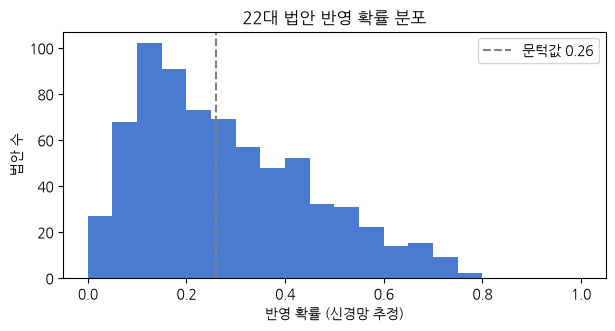

22대 위원회별 평균 확률: {'국토교통': 0.267, '행정안전': 0.316, '환경노동': 0.397}


In [26]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(out['PASS_PROB'], bins=20, range=(0, 1), color='#4a7bd0')
ax.axvline(THRESHOLD, color='gray', ls='--', label=f'문턱값 {THRESHOLD}')
ax.set_xlabel('반영 확률 (신경망 추정)'); ax.set_ylabel('법안 수'); ax.set_title('22대 법안 반영 확률 분포'); ax.legend()
plt.show()
print('22대 위원회별 평균 확률:', cur.assign(p=prob).groupby('COMM')['p'].mean().astype(float).round(3).to_dict())